# Approfondissement : pourquoi aucune des 7 stratégies connues ne marche ici, et que faudrait-il de vrai pour un Sharpe net > 2 ?

> **EXPLORATOIRE — ne modifie pas le verdict pré-enregistré.** Analyse a posteriori sur TRAIN (≤ 2018) et VAL (2019-2022). Le TEST (≥ 2023) reste scellé, aucun paramètre des sleeves n'est touché, `PREREGISTRATION.md` n'est pas modifié (pas de nouvel avenant).

Le verdict officiel est `ECHEC` (pile : Sharpe net VAL −5,30, brut −0,70). Ce carnet ne le rouvre pas : il **explique** l'échec avec sept
questions, chacune traitée de la même façon : *Question → Intuition → Théorème → Attente → Expérience → Résultat → Conclusion / limites*.

| # | Question | Outil |
|---|---|---|
| Q1 | Combien d'information, et sur combien de paris, faut-il pour un IR de 2 ? | loi fondamentale de Grinold / Clarke-de Silva-Thorley |
| Q2 | À quelle vitesse le signal s'éteint-il, et quel horizon le coût autorise-t-il ? | IC en fonction de l'horizon, horizon optimal sous coût |
| Q3 | Que peut-on conclure de 4 ans de VAL ? | erreur-type du Sharpe (Lo), puissance |
| Q4 | Que vaut un Sharpe trouvé après N essais ? | Sharpe maximal attendu sous H0 (Bailey-López de Prado) |
| Q5 | Pourquoi chaque sleeve échoue-t-elle ? | brut/net, Sharpe glissant, facteur de marché, régime |
| Q6 | La diversification peut-elle suffire ? | Sharpe d'une pile de N sleeves |
| Q7 | (bonus) Quelle capacité pour S1 et S6 ? | impact en racine carrée |

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))
from alpha import donnees as d, stats
from alpha.approfondissement import theorie, diagnostics as dg, chargement as ap

R = json.loads((RACINE / "results" / "approfondissement.json").read_text(encoding="utf-8"))
TV = json.loads((RACINE / "results" / "train_val.json").read_text(encoding="utf-8"))
FIG = RACINE / "figures"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200, "display.max_columns", 30)
print(R["titre"])
print("verdict officiel (inchangé) :", R["verdict_officiel_inchange"])
print("dernier jour de données utilisé :", R["meta"]["dernier_jour_utilise"], "(TEST >= 2023-01-01 jamais chargé)")


def aff(texte):
    display(Markdown(texte.replace("$", r"\$")))   # le signe $ des textes (Md$) ne doit pas ouvrir une formule

EXPLORATOIRE — non pré-enregistré, ne modifie pas le verdict
verdict officiel (inchangé) : {'verdict': 'ECHEC', 'statut_test': 'scelle_G1_ou_G2_en_echec'}
dernier jour de données utilisé : 2022-12-30 (TEST >= 2023-01-01 jamais chargé)


## Q1. Combien d'IC, sur combien de paris, pour un IR de 2 ?

> **EXPLORATOIRE — ne modifie pas le verdict pré-enregistré.** Analyse a posteriori sur TRAIN (≤ 2018) et VAL (2019-2022). Le TEST (≥ 2023) reste scellé, aucun paramètre des sleeves n'est touché, `PREREGISTRATION.md` n'est pas modifié (pas de nouvel avenant).

**Question.** Si une stratégie gagne `IC` de corrélation entre sa prévision et le rendement suivant, sur `BR` paris indépendants par an, quel Sharpe
peut-elle espérer ? Et pour viser 2 avec la breadth de nos 7 sleeves, quel IC faudrait-il ?

**Intuition.** Chaque pari est une loterie légèrement biaisée en notre faveur. Le biais (l'IC) est minuscule, mais on rejoue la loterie des centaines de fois par an
et le hasard se moyenne : le Sharpe grandit comme la racine du nombre de paris. Ce qu'on ne parvient pas à investir (tampon, 3 longs/3 courts, plafond) est perdu :
c'est le coefficient de transfert (TC).

**Théorème (Grinold 1989 ; Clarke-de Silva-Thorley 2002).** Avec des prévisions standardisées $s_i$ (variance 1) et un rendement normalisé de corrélation $\mathrm{IC}$ avec elles,
l'alpha attendu est $\alpha_i = \mathrm{IC}\,\sigma_i s_i$ ; les poids optimaux $w_i = \alpha_i/(\lambda\sigma_i^2)$ donnent $\mathrm{IR}^2=\sum_i (\alpha_i/\sigma_i)^2=\mathrm{IC}^2 \cdot \mathrm{BR}$, et si les
poids réellement tenus ont une corrélation $\mathrm{TC}$ avec les poids optimaux :

$$\boxed{\mathrm{IR} \;\approx\; \mathrm{TC}\times \mathrm{IC}\times\sqrt{\mathrm{BR}}}\qquad\Longrightarrow\qquad \mathrm{IC}^\star=\frac{\mathrm{IR}^\star}{\mathrm{TC}\sqrt{\mathrm{BR}}},\quad \mathrm{BR}^\star=\Big(\frac{\mathrm{IR}^\star}{\mathrm{TC}\cdot \mathrm{IC}}\Big)^2 .$$

**Attente.** Un IC « très bon » en gestion active vaut 0,05 (un IC de 0,1 est rarissime). Avec ~1 800 paris indépendants par an (breadth de la pile, très généreuse), IR = 2 exige un IC proche de 0,06 sur
**chaque** sleeve ; je m'attends donc à ce que nos IC, voisins de zéro, expliquent des Sharpe bruts voisins de zéro. Je m'attends aussi à ce que la loi *suive* le Sharpe brut réalisé (c'est une identité approchée).

**Expérience (1/2) : la loi sur un monde simulé.** On fabrique N actifs, une prévision de variance 1 et des rendements d'IC connu, on investit $w\propto f/\sigma$ chaque jour et on compare le Sharpe réalisé à $\mathrm{IC}\sqrt{N\cdot252}$.

In [2]:
def monde_simule(ic, n_actifs, n_jours=5040, graine=0):
    rng = np.random.default_rng(graine)
    f = rng.standard_normal((n_jours, n_actifs))                       # prévision standardisée
    sigma = 0.01
    r = sigma * (ic * f + np.sqrt(1 - ic ** 2) * rng.standard_normal((n_jours, n_actifs)))   # corr(f, r/sigma) = ic
    pnl = ((f / sigma) * r).sum(axis=1)                                 # poids proportionnels à f/sigma
    return stats.sharpe(pnl)

lignes = []
for ic in (0.01, 0.02, 0.05):
    for n in (10, 40):
        lignes.append({"IC": ic, "N actifs": n, "Sharpe simulé (20 ans)": monde_simule(ic, n),
                       "IC x racine(N x 252)": ic * np.sqrt(n * 252)})
display(pd.DataFrame(lignes).round(2))

,IC,N actifs,Sharpe simulé (20 ans),IC x racine(N x 252)
0,0.01,10,0.45,0.50
1,0.01,40,0.78,1.00
2,0.02,10,0.95,1.00
3,0.02,40,1.79,2.01
4,0.05,10,2.44,2.51
5,0.05,40,4.83,5.02


**Expérience (2/2) : les 7 sleeves.** Pour chaque sleeve et chaque période on mesure : l'IC (corrélation de rang entre la prévision, ou le poids, et le rendement suivant normalisé par la vol passée,
**exécuté à J+1** comme le moteur, à l'horizon de détention) ; la breadth (nombre effectif de paris indépendants des instruments, par la participation de la matrice de corrélation, × 252 / horizon de détention) ;
le TC (corrélation entre la prévision et la position pondérée du risque $w\sigma$). Contrôle de non-anticipation : les prévisions (sleeves + vol) ne dépendent pas du futur, vérifié par `tests/test_approfondissement_ic.py`.
Reproduction vivante d'une ligne (S2) depuis les données TRAIN/VAL (lecteur 1 h strict, minutes en cache) :

In [3]:
base = ap.charger_base()                      # cache pickle ou pipeline officiel ; TEST jamais lu
specs = dg.specs_quotidiennes(base)
sp = specs["S2"]
ligne = {}
for p, (a, b) in dg.PERIODES.items():
    s = dg.ic_serie(sp, 10)
    r = dg.resume_ic(s, max(a, base["res"]["S2"].debut), b, 10, sp.espacement)   # dès que la sleeve est active
    ligne[p] = (r["ic"], r["t_nw"])
ref = {p: (R["Q1_grinold"]["sleeves"]["S2"][p]["ic"], R["Q1_grinold"]["sleeves"]["S2"][p]["t_nw_ic"]) for p in ("TRAIN", "VAL")}
print("IC de S2 à 10 jours, recalculé ici :", {p: (round(v[0], 4), round(v[1], 2)) for p, v in ligne.items()})
print("valeurs du JSON                    :", {p: (round(v[0], 4), round(v[1], 2)) for p, v in ref.items()})
assert all(abs(ligne[p][0] - ref[p][0]) < 1e-9 for p in ligne)

IC de S2 à 10 jours, recalculé ici : {'TRAIN': (-0.0466, -2.04), 'VAL': (-0.0418, -1.2)}
valeurs du JSON                    : {'TRAIN': (-0.0466, -2.04), 'VAL': (-0.0418, -1.2)}


**Résultat.** Tableau complet (IC, TC, breadth, IR prédit, Sharpe brut réalisé, IC et breadth requis pour IR = 2).

IC   t NW     TC  N eff  breadth/an  IR prédit  Sharpe brut  écart (z)  IC requis IR=2  breadth requise
sleeve période                                                                                                            
S1     TRAIN   -0.012 -0.444  0.939  9.141     115.179     -0.119        0.227      0.790           0.198              NaN
       VAL     -0.044 -1.000  0.889  7.254      91.397     -0.372       -0.115      0.417           0.235              NaN
S2     TRAIN   -0.047 -2.043  0.872  6.107     153.886     -0.505       -0.350      0.374           0.185              NaN
       VAL     -0.042 -1.203  0.888  5.487     138.280     -0.437       -0.707     -0.442           0.192              NaN
S3     TRAIN   -0.016 -0.868  0.880  6.107     307.772     -0.254       -0.018      0.534           0.129              NaN
       VAL      0.004  0.156  0.877  5.487     276.560      0.061       -0.152     -0.339           0.137       296368.589
S6     TRAIN    0.041  0.563  1.000  1.958       8.224      0.118        0.564      1.102           0.698         2353.681
       VAL     -0.035 -0.453  1.000  1.791      22.572     -0.167        0.124      0.474           0.421              NaN
S4     TRAIN   -0.011 -1.022  0.999  4.376    1102.637     -0.356       -0.241      0.237           0.060              NaN
       VAL     -0.006 -0.415  0.998  3.919     987.569     -0.203        0.143      0.500           0.064              NaN
S5     TRAIN    0.042  0.782  0.964  2.474      29.689      0.218       -0.192     -0.924           0.381         2499.264
       VAL     -0.132 -1.611  0.957  1.999      23.992     -0.620       -0.147      0.758           0.427              NaN
S7     TRAIN   -0.016 -0.681  1.000  1.000     252.000     -0.251        0.035      0.562           0.126              NaN
       VAL     -0.070 -2.141  1.000  1.000     252.000     -1.114       -1.292     -0.250           0.126              NaN

,TRAIN,VAL
breadth_totale,1969.388,1792.370
tc_moyen,0.951,0.944
ir_pile_predit_risque_egal,-0.434,-1.078
ic_uniforme_requis_pour_ir_2,0.057,0.059
ic_moyen_observe,-0.003,-0.047


accord prédit/réalisé : {'n_couples': 14, 'correlation': 0.7638982292060665, 'correlation_rang_spearman': 0.6}


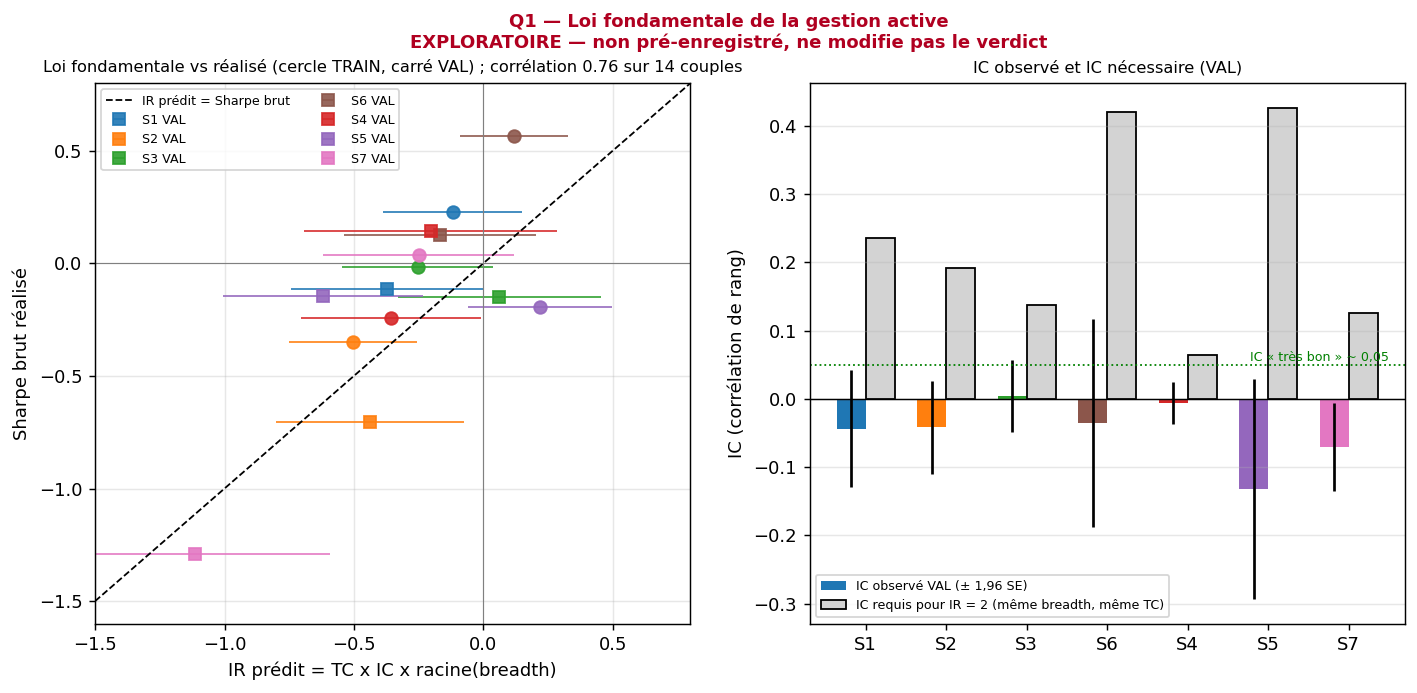

In [4]:
lignes = []
for nom, blocs in R["Q1_grinold"]["sleeves"].items():
    for p, b in blocs.items():
        lignes.append({"sleeve": nom, "période": p, "IC": b["ic"], "t NW": b["t_nw_ic"], "TC": b["tc"], "N eff": b["n_effectif"],
                       "breadth/an": b["breadth"], "IR prédit": b.get("ir_predit"), "Sharpe brut": b["sharpe_brut"],
                       "écart (z)": b.get("z_ecart_predit_vs_realise"), "IC requis IR=2": b.get("ic_requis_pour_ir_2"),
                       "breadth requise": b.get("breadth_requise_pour_ir_2")})
display(pd.DataFrame(lignes).set_index(["sleeve", "période"]).round(3))
pile = R["Q1_grinold"]["pile"]
display(pd.DataFrame({p: pile[p] for p in ("TRAIN", "VAL")}).round(3))
print("accord prédit/réalisé :", pile["accord_predit_realise"])
display(Image(str(FIG / "appro_q1_grinold.png")))

**Conclusion / limites.**

In [5]:
aff(R["conclusions"]["Q1"])

La loi IR = TC x IC x racine(BR) prédit le Sharpe brut réalisé avec une corrélation de 0,76 sur 14 couples (sleeve, période) : l'ordre de grandeur tient (écart prédit - réalisé |z| <= 1,1 sur les 14 couples, mais les erreurs-types sont larges), donc ce qui manque est de l'IC, pas de la breadth. Avec une breadth totale de 1792 paris indépendants/an et un TC moyen de 0,94, une pile à IR 2 exigerait un IC de 0,059 sur les 7 sleeves à la fois ; l'IC moyen observé en VAL vaut -0,047 (S1 -0,044, S2 -0,042, S3 0,004, S7 -0,070). Avec l'IC observé de S3 (le seul positif parmi les sleeves quotidiennes), il faudrait 1072 fois sa breadth.

*Limites.* La breadth est une notion fragile : la participation (nombre effectif d'instruments) ignore la corrélation *temporelle* des signaux lents, d'où l'horizon de détention au dénominateur. L'IC de S6 contient la prime de risque
actions (sleeve long seul) : la loi décrit l'IR *actif*, pas le Sharpe total d'un bêta. L'IC de chaque période est lui-même bruité (t de Newey-West ≤ 2 presque partout) : l'accord avec le Sharpe réalisé est un ordre de grandeur sur
14 couples, pas une preuve. Les sleeves intrajournalières (S4, S5, S7) ont un IC mesuré sur toute la fenêtre ; leur TC vaut ≈ 1 par construction (poids = direction × k / σ).

## Q2. À quelle vitesse le signal s'éteint-il, et quel horizon le coût autorise-t-il ?

> **EXPLORATOIRE — ne modifie pas le verdict pré-enregistré.** Analyse a posteriori sur TRAIN (≤ 2018) et VAL (2019-2022). Le TEST (≥ 2023) reste scellé, aucun paramètre des sleeves n'est touché, `PREREGISTRATION.md` n'est pas modifié (pas de nouvel avenant).

**Question.** L'IC dépend de l'horizon sur lequel on mesure le rendement suivant. Où le signal paie-t-il, combien de temps vit-il, et comment l'horizon se règle-t-il contre le coût de rotation ?

**Intuition.** Un signal est une information périssable : plus on attend, moins elle vaut. Pour la monétiser il faut la porter ; mais chaque changement de position coûte. Il y a donc une durée de portage optimale :
tenir trop peu paie trop de coûts, tenir trop longtemps fait porter une information morte.

**Théorème (horizon optimal sous coût).** Si le gain cumulé de prévision à l'horizon $h$ est $G(h)=A\,(1-e^{-h/\tau})$ et si chaque ré-signalisation coûte $C$, le rendement net **par jour** est $N(h)=\dfrac{G(h)-C}{h}$.
Son maximum vérifie $N'(h)=0 \iff G'(h^\star)=N(h^\star)$ (le gain marginal égale le rendement net moyen) soit, avec $u=h/\tau$ :

$$1-(1+u^\star)\,e^{-u^\star}=\frac{C}{A},\qquad h^\star=\tau\,u^\star\;\approx\;\tau\sqrt{2C/A}\ \text{ si } C\ll A ;\quad \text{pas de solution (jamais rentable) si } C\ge A .$$

**Attente.** Un signal de momentum doit avoir un IC croissant avec l'horizon puis décroissant ; un signal de retournement court doit avoir un IC fort à court terme et nul au-delà ; les signaux intrajournaliers doivent s'éteindre en minutes.
Je m'attends à ce que S2 et S3 ne soient pas aux horizons où leur règle les tient (63 j de momentum tenu 1-2 semaines ; 5 j de retournement tenu 1 semaine).

**Expérience (1/2) : le théorème sur un signal à décroissance exponentielle connue.**

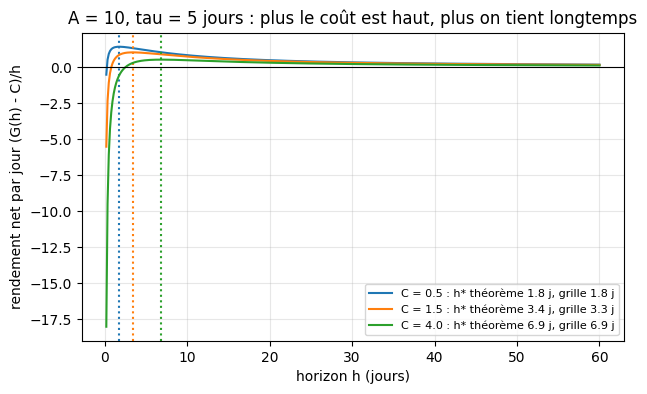

In [6]:
A, tau = 10.0, 5.0
fig, ax = plt.subplots(figsize=(7, 4))
h = np.linspace(0.2, 60, 400)
for cout, c in ((0.5, "C0"), (1.5, "C1"), (4.0, "C2")):
    hs = theorie.horizon_optimal_exponentiel(A, tau, cout)
    grille = h[np.argmax(theorie.rendement_net_par_jour(h, A, tau, cout))]
    ax.plot(h, theorie.rendement_net_par_jour(h, A, tau, cout), color=c, label=f"C = {cout} : h* théorème {hs:.1f} j, grille {grille:.1f} j")
    ax.axvline(hs, color=c, ls=":")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("horizon h (jours)"); ax.set_ylabel("rendement net par jour (G(h) - C)/h"); ax.legend(fontsize=8)
ax.set_title("A = 10, tau = 5 jours : plus le coût est haut, plus on tient longtemps")
plt.show()

**Expérience (2/2) : les 7 sleeves.** IC cumulé à 1, 2, 5, 10, 20, 60 jours (S1, S2, S3, S6 ; exécution à J+1), IC *marginal* du seul jour h (demi-vie de l'IC), autocorrélation du signal (demi-vie du signal), profil gain/coût de re-signalisation
(S1, S2, S3), et pour S4, S5, S7 l'IC en minutes sur le 1 minute (cache TRAIN/VAL). Reproduction vivante de la courbe de S3 :

In [7]:
sp3 = specs["S3"]
H = dg.H_GRILLE
vivant = {h: dg.resume_ic(dg.ic_serie(sp3, h), d.DEBUT_DONNEES, d.FIN_VAL, h, sp3.espacement)["ic"] for h in H}
json_ = {h: R["Q2_decroissance"]["sleeves_quotidiennes"]["S3"]["ic"]["cumule"]["TOUT"][str(h)]["ic"] for h in H}
print("IC cumulé de S3 (TRAIN+VAL) recalculé :", {h: round(v, 4) for h, v in vivant.items()})
assert all(abs(vivant[h] - json_[h]) < 1e-9 for h in H)

IC cumulé de S3 (TRAIN+VAL) recalculé : {1: 0.0019, 2: -0.0204, 5: -0.0095, 10: 0.0185, 20: 0.0232, 60: 0.0409}


**Résultat.**

In [8]:
q2 = R["Q2_decroissance"]
lignes = []
for nom, s in q2["sleeves_quotidiennes"].items():
    for p in ("TRAIN", "VAL", "TOUT"):
        lignes.append({"sleeve": nom, "période": p, **{f"h={h}": s["ic"]["cumule"][p][str(h)]["ic"] for h in dg.H_GRILLE}})
display(pd.DataFrame(lignes).set_index(["sleeve", "période"]).round(3))
print("t de Newey-West de l'IC cumulé TRAIN+VAL :")
display(pd.DataFrame({nom: {f"h={h}": s["ic"]["cumule"]["TOUT"][str(h)]["t_nw"] for h in dg.H_GRILLE} for nom, s in q2["sleeves_quotidiennes"].items()}).T.round(1))
dv = pd.DataFrame({nom: {"demi-vie du signal (j)": s["demi_vie_signal_jours"], "demi-vie IC TRAIN (j)": s["demi_vie_ic_marginal_jours"]["TRAIN"],
                         "demi-vie IC VAL (j)": s["demi_vie_ic_marginal_jours"]["VAL"]} for nom, s in q2["sleeves_quotidiennes"].items()}).T
display(dv.round(1))

h=1    h=2    h=5   h=10   h=20   h=60
sleeve période                                          
S1     TRAIN   -0.000 -0.004 -0.012 -0.013 -0.012 -0.029
       VAL      0.003 -0.002 -0.015 -0.029 -0.044 -0.001
       TOUT     0.001 -0.003 -0.013 -0.018 -0.023 -0.020
S2     TRAIN    0.014 -0.012 -0.023 -0.048 -0.063 -0.098
       VAL     -0.049 -0.035 -0.033 -0.042 -0.073 -0.135
       TOUT    -0.006 -0.019 -0.026 -0.046 -0.066 -0.109
S3     TRAIN    0.000 -0.028 -0.016  0.019  0.024  0.044
       VAL      0.005 -0.003  0.004  0.017  0.022  0.034
       TOUT     0.002 -0.020 -0.009  0.018  0.023  0.041
S6     TRAIN   -0.013  0.009 -0.060 -0.059  0.046  0.041
       VAL     -0.221 -0.100 -0.103  0.014 -0.035  0.084
       TOUT    -0.082 -0.027 -0.074 -0.035  0.019  0.055

t de Newey-West de l'IC cumulé TRAIN+VAL :


,h=1,h=2,h=5,h=10,h=20,h=60
S1,0.1,-0.4,-1.0,-1.1,-1.0,-0.5
S2,-0.4,-1.3,-1.6,-2.4,-2.7,-3.2
S3,0.1,-1.3,-0.6,1.2,1.6,2.8
S6,-1.5,-0.5,-1.2,-0.6,0.4,0.9


,demi-vie du signal (j),demi-vie IC TRAIN (j),demi-vie IC VAL (j)
S1,64.7,NaN,NaN
S2,29.6,21.7,NaN
S3,2.4,NaN,9.6
S6,58.4,NaN,NaN


h                 1     2     5     10    20    60
sleeve période                                    
S1     TRAIN   -0.45 -0.44 -0.42 -0.26 -0.10 -0.16
       VAL     -0.24 -0.32 -0.29 -0.30 -0.27  0.01
S2     TRAIN     NaN   NaN -0.86 -0.88 -0.79 -0.52
       VAL       NaN   NaN -1.01 -0.97 -1.01 -0.93
S3     TRAIN     NaN   NaN -0.21  0.12  0.23  0.22
       VAL       NaN   NaN -0.58 -0.23  0.16  0.32

**S4** : IC de rang (haut) et gain brut moyen par trade en bps (bas) selon les minutes après l'entrée ; coût aller-retour moyen 1.96 bps.

,5 min,15 min,30 min,60 min,120 min,240 min,360 min
TRAIN,-0.027,-0.012,-0.006,-0.012,-0.011,-0.009,-0.011
VAL,-0.048,-0.035,-0.011,0.016,-0.013,-0.000,-0.006
TOUT,-0.034,-0.019,-0.007,-0.003,-0.011,-0.007,-0.010


,5 min,15 min,30 min,60 min,120 min,240 min,360 min
TRAIN,-0.15,-0.10,-0.09,-0.07,-0.06,-0.05,-0.16
VAL,-0.21,-0.17,-0.07,0.39,0.05,0.20,-0.08
TOUT,-0.17,-0.12,-0.09,0.07,-0.02,0.03,-0.13


**S5** : IC de rang (haut) et gain brut moyen par trade en bps (bas) selon les minutes après l'entrée ; coût aller-retour moyen 1.24 bps.

...

**S7** : IC de rang (haut) et gain brut moyen par trade en bps (bas) selon les minutes après l'entrée ; coût aller-retour moyen 24.00 bps.

,1 min,5 min,10 min,15 min,20 min,30 min
TRAIN,-0.042,-0.038,-0.032,-0.016,-0.019,-0.016
VAL,0.019,-0.015,-0.038,-0.034,-0.010,-0.070
TOUT,-0.018,-0.030,-0.034,-0.021,-0.017,-0.036


,1 min,5 min,10 min,15 min,20 min,30 min
TRAIN,-0.17,-0.36,-0.46,-0.21,-0.49,-0.05
VAL,-0.14,-0.44,-0.93,-0.83,-0.56,-1.90
TOUT,-0.16,-0.39,-0.62,-0.41,-0.51,-0.66


**S7, IC du signal du matin (16h→10h) sur chaque demi-heure de la séance** (début du bloc, heure de New York ; entre parenthèses le t de Newey-West). Blocs où le même signe tient avec |t| > 2 en TRAIN **et** en VAL : aucun.

,TRAIN,VAL
10:00,-0.017 (t -0.7),-0.004 (t -0.1)
10:30,-0.026 (t -1.2),+0.002 (t +0.1)
11:00,-0.009 (t -0.4),-0.026 (t -0.8)
11:30,+0.031 (t +1.4),+0.051 (t +1.6)
12:00,+0.095 (t +4.0),-0.034 (t -1.1)
12:30,-0.026 (t -1.1),+0.093 (t +3.1)
13:00,+0.001 (t +0.1),-0.016 (t -0.5)
13:30,+0.009 (t +0.4),+0.029 (t +0.9)
14:00,+0.049 (t +2.2),-0.017 (t -0.5)
14:30,+0.034 (t +1.4),-0.009 (t -0.3)


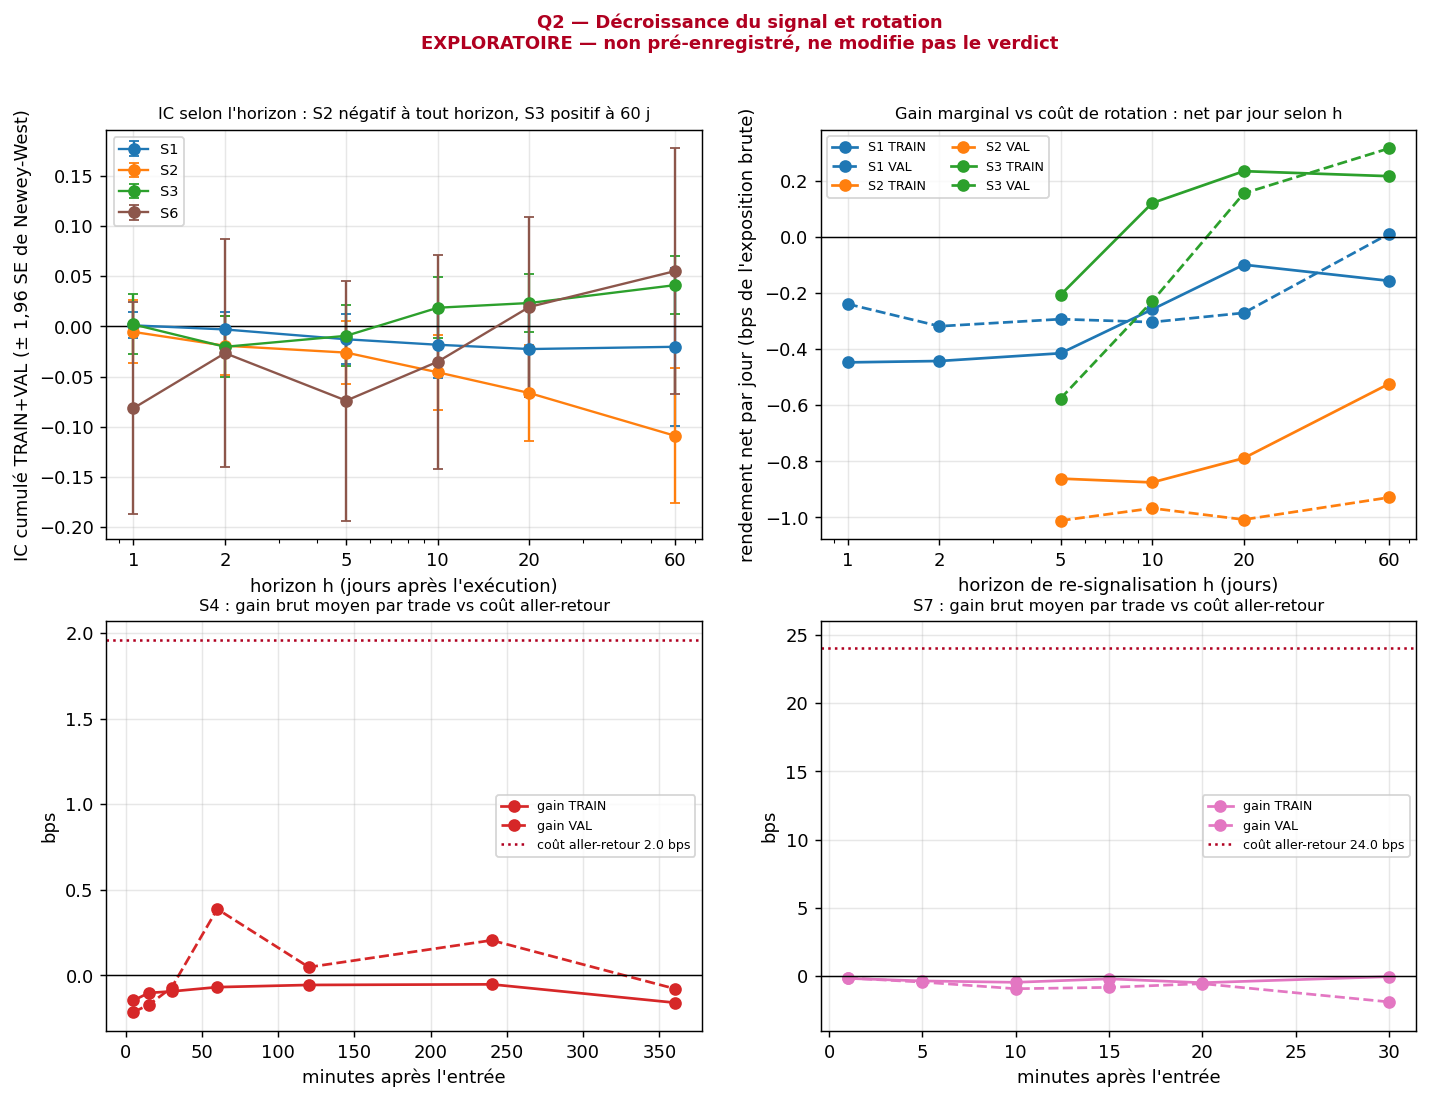

In [9]:
lignes = []
for nom in ("S1", "S2", "S3"):
    pg = q2["sleeves_quotidiennes"][nom]["profil_gain_cout"]
    for p in ("TRAIN", "VAL"):
        for h in dg.H_GRILLE:
            x = pg[p][str(h)]
            if x:
                lignes.append({"sleeve": nom, "période": p, "h": h, "gain brut (bps)": x["gain_bps"], "coût (bps)": x["cout_bps"], "net bps/jour": x["net_bps_par_jour"]})
tab = pd.DataFrame(lignes)
display(tab.pivot_table(index=["sleeve", "période"], columns="h", values="net bps/jour").round(2))
for nom in ("S4", "S5", "S7"):
    mm = q2["minutes"][nom]
    cout = next(v["cout_aller_retour_bps"] for v in mm["TOUT"].values() if v)
    display(Markdown(f"**{nom}** : IC de rang (haut) et gain brut moyen par trade en bps (bas) selon les minutes après l'entrée ; coût aller-retour moyen {cout:.2f} bps."))
    cles = sorted(mm["TOUT"], key=int)
    display(pd.DataFrame({p: {f"{k} min": mm[p][k]["ic"] if mm[p][k] else None for k in cles} for p in ("TRAIN", "VAL", "TOUT")}).T.round(3))
    display(pd.DataFrame({p: {f"{k} min": mm[p][k]["gain_bps"] if mm[p][k] else None for k in cles} for p in ("TRAIN", "VAL", "TOUT")}).T.round(2))
delais = q2["minutes"]["S7_delai_bloc_30min"]
repliquent = [h for h, v in delais.items() if abs(v["TRAIN"]["30"]["t_nw"]) > 2 and abs(v["VAL"]["30"]["t_nw"]) > 2
              and np.sign(v["TRAIN"]["30"]["ic"]) == np.sign(v["VAL"]["30"]["ic"])]
display(Markdown("**S7, IC du signal du matin (16h→10h) sur chaque demi-heure de la séance** (début du bloc, heure de New York ; entre parenthèses le t de Newey-West). "
                 f"Blocs où le même signe tient avec |t| > 2 en TRAIN **et** en VAL : {repliquent if repliquent else 'aucun'}."))
display(pd.DataFrame({h: {p: f"{v[p]['30']['ic']:+.3f} (t {v[p]['30']['t_nw']:+.1f})" for p in ("TRAIN", "VAL")} for h, v in delais.items()}).T)
display(Image(str(FIG / "appro_q2_decroissance.png")))

**Conclusion / limites.**

In [10]:
aff(R["conclusions"]["Q2"])

IC de S2 (momentum 63 j) négatif à tous les horizons testés sur TRAIN+VAL (60 j : -0,109, t = -3,2) : le signal est inversé. IC de S3 (retournement 5 j) négatif à 2-5 j, positif à 10-60 j (60 j : 0,041, t = 2,8) alors que S3 est tenue 5 jours ; en re-signalisant tous les 60 j le net par jour serait de 0,22 bps (TRAIN) et 0,32 bps (VAL) de l'exposition brute (constat a posteriori : il faudrait un nouveau pré-enregistrement). Demi-vie du signal : S1 65 j, S2 30 j, S3 2 j, S6 58 j ; la demi-vie de l'IC n'est définie que pour 2 des 8 couples (sleeve, période) car l'IC est le plus souvent <= 0. Intrajournalier : gain brut moyen maximal de S4 0,39 bps contre 2,0 bps de coût aller-retour ; S7 au mieux -0,05 bps contre 24 bps.

*Limites.* (1) Les constats sur S3 et S2 sont **a posteriori** : six horizons × quatre sleeves × trois périodes ont été regardés ; un IC à t ≈ 2,8 parmi tant de lectures peut être de la chance. Ils indiquent où chercher dans un NOUVEAU pré-enregistrement
(avec N cumulé), pas une sleeve à rajouter. (2) Le profil gain/coût utilise des positions « de principe » (signe de la prévision ; 3 meilleurs / 3 pires), pas les poids exacts des sleeves, et un coût de re-signalisation constant par jambe.
(3) La demi-vie de l'IC n'est définie que si l'IC marginal est positif et décroissant sur au moins 3 points : ici elle l'est rarement, ce qui est déjà une information.

## Q3. Que peut-on conclure de 4 ans de VAL ?

> **EXPLORATOIRE — ne modifie pas le verdict pré-enregistré.** Analyse a posteriori sur TRAIN (≤ 2018) et VAL (2019-2022). Le TEST (≥ 2023) reste scellé, aucun paramètre des sleeves n'est touché, `PREREGISTRATION.md` n'est pas modifié (pas de nouvel avenant).

**Question.** Quelle est l'incertitude d'un Sharpe estimé sur 1 044 jours, quel Sharpe vrai peut-on détecter avec 80 % de puissance, et quelle est la probabilité qu'une stratégie de vrai Sharpe 0,5 affiche un Sharpe VAL aussi mauvais que celui observé ?

**Intuition.** Un Sharpe est une moyenne divisée par un écart-type : sa précision dépend du nombre d'observations, pas du nombre de lignes de code. Quatre ans de données donnent un Sharpe à ±1 près : il est impossible de distinguer un vrai 0,5 d'un vrai 0.

**Théorème (Lo 2002 ; Mertens 2002).** Pour des rendements iid, le Sharpe par jour estimé a une variance asymptotique $\dfrac{1+\tfrac12 SR_j^2}{n}$ ; avec asymétrie $\gamma_3$ et kurtosis $\gamma_4$ (Mertens) : $\dfrac{1-\gamma_3 SR_j+\tfrac{\gamma_4-1}{4}SR_j^2}{n}$.
Annualisé ($SR=\sqrt{252}\,SR_j$, $Y=n/252$ années) : $\mathrm{SE}(SR)=\sqrt{\dfrac{1+SR^2/504}{Y}}\approx \dfrac1{\sqrt Y}$.
Le plus petit Sharpe vrai détecté avec une puissance $1-\beta$ par un test unilatéral de niveau $\alpha$ est

$$SR_{\min}=z_{1-\alpha}\,\mathrm{SE}(0)+z_{1-\beta}\,\mathrm{SE}(SR_{\min})\approx\frac{z_{1-\alpha}+z_{1-\beta}}{\sqrt Y},\qquad Y_{\text{requis}}(SR)=\Big(\frac{z_{1-\alpha}+z_{1-\beta}\sqrt{1+SR^2/504}}{SR}\Big)^2 .$$

**Attente.** SE ≈ 0,5 ; $SR_{\min}\approx 1{,}2$ (1,6 avec Bonferroni sur 7 sleeves) ; il faut ~25 ans pour confirmer un vrai Sharpe de 0,5. Donc les sleeves à Sharpe VAL proche de zéro ne sont pas « prouvées nulles ».

**Expérience.** (a) Monte-Carlo de la formule sur du bruit blanc ; (b) probabilité $P(\widehat{SR}\le SR_{\text{obs}}\mid SR_{\text{vrai}}=0{,}5)$ par trois méthodes : analytique, simulation paramétrique, bootstrap stationnaire (blocs de 20 jours) qui recentre les rendements *observés* de la sleeve.

In [11]:
rng = np.random.default_rng(1)
n = 1044
x = rng.standard_normal((4000, n))
sh = x.mean(axis=1) / x.std(axis=1, ddof=1) * np.sqrt(252)
print(f"écart-type empirique du Sharpe sur bruit blanc : {sh.std(ddof=1):.3f}   formule de Lo : {theorie.se_sharpe(0.0, n):.3f}")
print("Sharpe minimal détectable à 80 % (4 ans) :", {k: round(v, 2) for k, v in R["Q3_puissance"]["sharpe_min_detectable_80pct"].items()})
print("années pour détecter (80 %, unilatéral 5 %) :", {k: round(v, 1) for k, v in R["Q3_puissance"]["annees_pour_detecter_80pct_unilateral"].items()})

écart-type empirique du Sharpe sur bruit blanc : 0.495   formule de Lo : 0.491
Sharpe minimal détectable à 80 % (4 ans) : {'unilateral_alpha5': 1.22, 'bilateral_alpha5': 1.38, 'unilateral_bonferroni_7': 1.62, 'bilateral_bonferroni_7': 1.74}
années pour détecter (80 %, unilatéral 5 %) : {'0.25': 98.9, '0.5': 24.7, '1.0': 6.2, '2.0': 1.5}


**Résultat.**

,Sharpe net VAL,SE Lo,SE Mertens,kurtosis,"P(vrai 0,5) analytique","P(vrai 0,5) paramétrique","P(vrai 0,5) bootstrap","P(vrai 0,25) analytique","P(vrai 1,0) analytique"
S1,-0.2009,0.4913,0.4900,5.0790,0.0769,0.0753,0.0447,0.1794,0.0073
S2,-0.8160,0.4916,0.4917,4.8171,0.0037,0.0035,0.0023,0.0150,0.0001
S3,-0.4925,0.4914,0.4908,4.1474,0.0217,0.0222,0.0097,0.0654,0.0012
S4,-1.8144,0.4929,0.5058,5.1179,0.0000,0.0000,0.0000,0.0000,0.0000
S5,-0.4929,0.4914,0.4933,68.1634,0.0217,0.0222,0.0193,0.0653,0.0012
S6,0.0651,0.4913,0.4925,9.9263,0.1881,0.1898,0.1740,0.3534,0.0287
S7,-12.3435,0.5607,0.7469,13.1523,0.0000,0.0000,0.0000,0.0000,0.0000
PILE,-5.3021,0.5048,0.4656,6.9307,0.0000,0.0000,0.0000,0.0000,0.0000


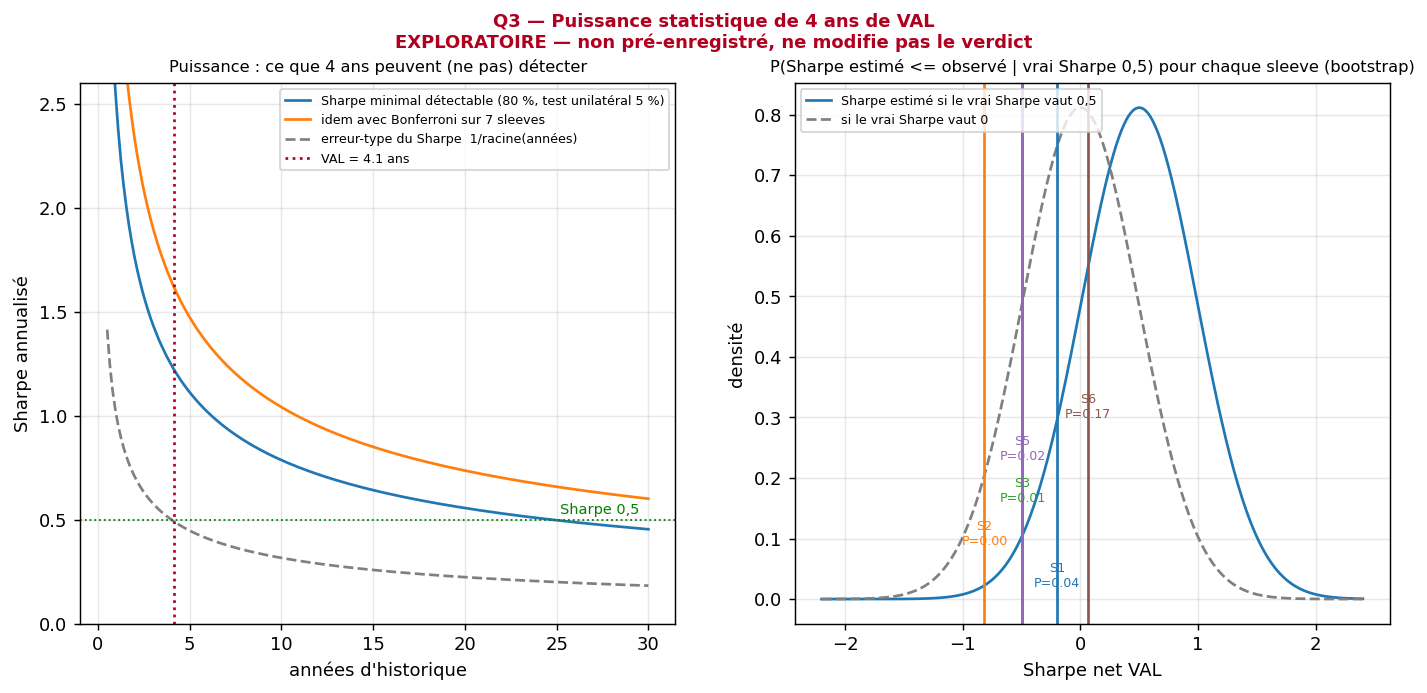

In [12]:
ps = R["Q3_puissance"]["par_serie"]
display(pd.DataFrame({k: {"Sharpe net VAL": v["sharpe_net_val"], "SE Lo": v["se_lo_gaussienne"], "SE Mertens": v["se_mertens_asym_kurt"], "kurtosis": v["kurtosis"],
                          "P(vrai 0,5) analytique": v["p_sharpe_vrai_05_donne_au_plus_obs"]["analytique"],
                          "P(vrai 0,5) paramétrique": v["p_sharpe_vrai_05_donne_au_plus_obs"]["parametrique"],
                          "P(vrai 0,5) bootstrap": v["p_sharpe_vrai_05_donne_au_plus_obs"]["bootstrap"],
                          "P(vrai 0,25) analytique": v["p_sharpe_vrai_025_donne_au_plus_obs_analytique"],
                          "P(vrai 1,0) analytique": v["p_sharpe_vrai_10_donne_au_plus_obs_analytique"]} for k, v in ps.items()}).T.round(4))
display(Image(str(FIG / "appro_q3_puissance.png")))

**Conclusion / limites.**

In [13]:
aff(R["conclusions"]["Q3"])

Sur 4,1 ans de VAL l'erreur-type du Sharpe vaut 0,49 ; le plus petit Sharpe vrai détecté avec 80 % de puissance est 1,22 (unilatéral 5 %), 1,62 avec Bonferroni sur 7 sleeves. Détecter un Sharpe de 0,5 exige 25 ans, de 0,25 : 99 ans. Une sleeve de vrai Sharpe 0,5 afficherait un Sharpe VAL <= celui de S6 (0,07) avec 17 % de chances, <= celui de S1 (-0,20) avec 4,5 % (bootstrap ; 7,7 % en analytique) : un vrai Sharpe de 0,5 est écarté (P < 3 %, bootstrap) pour S2, S3, S4, S5, S7 mais pas pour S1, S6. Absence de preuve n'est pas preuve d'absence : un vrai Sharpe de 0,25 n'est écarté (P < 5 %) que pour S2, S4, S7.

*Limites.* La SE de Lo suppose des rendements iid ; l'autocorrélation (positions persistantes) et les queues épaisses la modifient (SE de Mertens ci-dessus, bootstrap par blocs), mais pas l'ordre de grandeur. Les probabilités conditionnelles à
« vrai Sharpe = 0,5 » sont des tests d'hypothèse ponctuelle, pas des probabilités a posteriori que la sleeve soit à 0,5.

## Q4. Que vaut un Sharpe trouvé après N essais ?

> **EXPLORATOIRE — ne modifie pas le verdict pré-enregistré.** Analyse a posteriori sur TRAIN (≤ 2018) et VAL (2019-2022). Le TEST (≥ 2023) reste scellé, aucun paramètre des sleeves n'est touché, `PREREGISTRATION.md` n'est pas modifié (pas de nouvel avenant).

**Question.** Si on teste N stratégies sans aucun edge, quel est le meilleur Sharpe qu'on trouvera en moyenne ? Que valent N = 8 (ce projet) et les nombres d'essais déclarés par un projet de recherche antérieur (non publié) ? Que dire d'un « Sharpe > 2 » obtenu par recherche répétée ?

**Intuition.** Le meilleur de N loteries est meilleur que la loterie moyenne, mécaniquement. Un backtest court a des Sharpe très dispersés (SE élevée), donc le meilleur de beaucoup d'essais a l'air excellent par pur hasard.

**Théorème (Bailey-López de Prado 2014).** Pour N Sharpe estimés indépendants, centrés en 0, d'écart-type $\sigma$, avec $\gamma\approx0{,}5772$ la constante d'Euler-Mascheroni :

$$\mathbb E[\max_N \widehat{SR}]\;\approx\;\sigma\Big((1-\gamma)\,\Phi^{-1}\!\big(1-\tfrac1N\big)+\gamma\,\Phi^{-1}\!\big(1-\tfrac1{Ne}\big)\Big),\qquad \mathbb P(\max_N\ge x)=1-\Phi(x/\sigma)^N .$$

**Attente.** Avec $\sigma=\mathrm{SE}$ d'un Sharpe VAL ≈ 0,49 : N = 8 → ≈ 0,7 ; N = 134 → ≈ 1,3 ; un Sharpe de 2 par pur hasard demande des milliers d'essais sur 4 ans mais seulement ~25 sur 1 an.

**Expérience.** On vérifie la formule par simulation de N stratégies de bruit blanc (1 044 jours), puis on l'applique aux nombres d'essais **déclarés** par ce projet antérieur non publié (rien n'est estimé).

In [14]:
sig = theorie.se_sharpe(0.0, 1044)
lignes = []
for N in (2, 8, 50):
    moy, sd = theorie.simuler_sharpe_max(N, 1044, n_rep=400, graine=N)
    lignes.append({"N": N, "formule": theorie.sharpe_max_attendu(N, sig), "exact gaussien": theorie.esperance_max_gaussien(N) * sig, "simulation (400 rép.)": moy})
display(pd.DataFrame(lignes).round(3))

,N,formule,exact gaussien,simulation (400 rép.)
0,2,0.255,0.277,0.299
1,8,0.717,0.699,0.681
2,50,1.118,1.105,1.122


**Résultat.**

,formule,exact_gaussien,simulation_moyenne,simulation_ecart_type
2,0.255,0.277,0.252,0.411
4,0.517,0.506,0.511,0.347
8,0.717,0.699,0.707,0.303
20,0.934,0.917,0.931,0.259
50,1.118,1.105,1.116,0.231
134,1.293,1.283,1.291,0.211


,n_essais,source,sharpe_max_attendu_sigma_val,p_au_moins_un_sharpe_2
noeud,,,,
exploration A,9,nombre d'essais déclaré (projet antérieur non ...,0.7472,0.0002
exploration B,6,nombre d'essais déclaré (projet antérieur non ...,0.6388,0.0001
exploration C,12,nombre d'essais déclaré (projet antérieur non ...,0.8179,0.0003
exploration D,39,nombre d'essais déclaré (projet antérieur non ...,1.0708,0.0009
exploration E,50,nombre d'essais déclaré (projet antérieur non ...,1.1184,0.0012
exploration F,134,"plancher déclaré (« pas un plafond »), projet ...",1.2931,0.0031


,sigma_sr,N pour un Sharpe 2 par hasard
1,1.000,26.0
2,0.707,243.0
4,0.500,17845.0
8,0.354,73091818.0


N pour que le hasard fabrique un Sharpe de ... sur 4 ans : {'0.5': 4, '1.0': 28, '1.5': 501, '2.0': 24121}
illustration : {'n': 1770, 'origine': "nombre de paires (60·59/2) d'un univers de 60 actifs : une illustration de sélection « la meilleure paire », PAS un compte d'essais documenté", 'sharpe_max_attendu_sans_edge': 1.677365384216775}


,SR0 annualisé
prereg (variance observée des 8 Sharpe),6.23
"théorique (variance = SE², N = 8)",0.72


S1      0.0306
S2      0.0009
S3      0.0069
S4      0.0000
S5      0.0071
S6      0.0930
S7      0.0000
PILE    0.0000
Name: PSR contre le SR0 théorique (exploratoire), dtype: float64

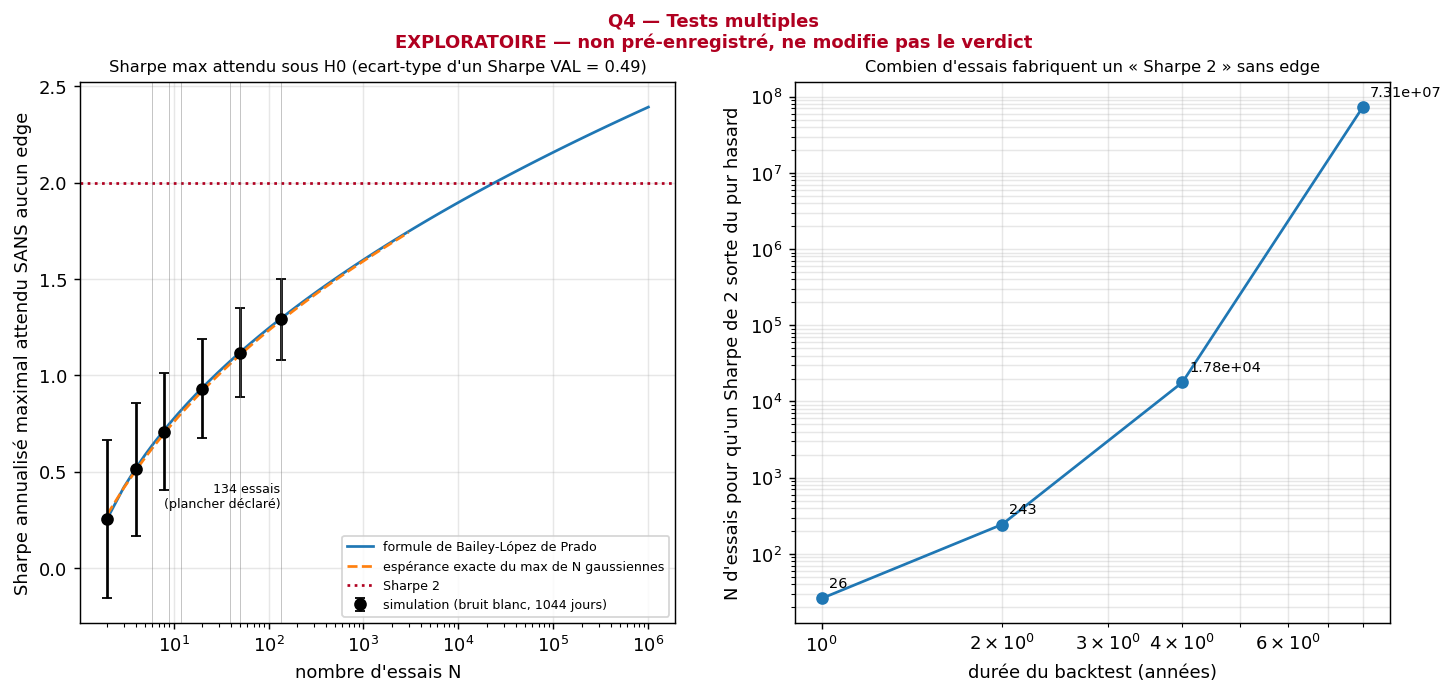

In [15]:
q4 = R["Q4_tests_multiples"]
display(pd.DataFrame(q4["validation_formule_vs_simulation"]).T.round(3))
display(pd.DataFrame(q4["historique_essais_anterieurs"]).set_index("noeud").round(4))
display(pd.DataFrame(q4["n_essais_pour_sharpe_2_selon_duree_backtest_annees"]).T.rename(columns={"n_essais_pour_sr_attendu_2": "N pour un Sharpe 2 par hasard"}).round(3))
print("N pour que le hasard fabrique un Sharpe de ... sur 4 ans :", {k: round(v) for k, v in q4["n_essais_pour_sharpe_cible_sur_4_ans"].items()})
print("illustration :", q4["illustration_selection_1770_paires"])
display(pd.DataFrame({"SR0 annualisé": {"prereg (variance observée des 8 Sharpe)": q4["dsr"]["sr0_annualise_prereg_variance_observee"],
                                         "théorique (variance = SE², N = 8)": q4["dsr"]["sr0_annualise_variance_theorique"]}}).round(2))
display(pd.Series(q4["dsr"]["psr_contre_sr0_theorique_exploratoire"], name="PSR contre le SR0 théorique (exploratoire)").round(4))
display(Image(str(FIG / "appro_q4_tests_multiples.png")))

**Conclusion / limites.**

In [16]:
aff(R["conclusions"]["Q4"])

Sharpe maximal attendu sans aucun edge : 0,72 pour N = 8 (simulation 0,71), 1,29 pour N = 134, plancher d'essais déclaré par un projet antérieur (simulation 1,29) ; P(au moins un Sharpe VAL >= 2 par hasard | N = 134) = 0,3 %. Sur la durée de VAL (4,1 ans) le hasard seul fabrique un Sharpe de 1 après 28 essais et de 2 après 24121 ; selon la durée du backtest, un Sharpe de 2 sort du hasard après 26 essais (1 an), 243 (2 ans), 17845 (4 ans), 7.3e+07 (8 ans). Choisir la meilleure des 1770 paires d'un univers de 60 actifs donnerait 1,68 sans edge (hypothèse : essais indépendants). Conséquence : un « Sharpe > 2 » issu d'une recherche répétée n'a de sens qu'après déflation par le N réel ; le SR0 du prereg (6,23) est tiré par S7, le seuil théorique est 0,72 (le verdict ne change pas).

*Limites.* La formule suppose des essais indépendants et de même variance ; les essais du projet antérieur sont fortement corrélés (mêmes données, variantes d'une idée), donc le N *effectif* est plus petit que N, et le seuil plus bas. Le projet ne tient pas de
compteur cumulé unique : 134 est un plancher déclaré par ce projet antérieur, pas une mesure. Les « 1 770 paires » (60·59/2) ne sont pas un compte d'essais, seulement l'illustration d'une sélection de la meilleure paire. Le seuil théorique ci-dessus est un
diagnostic exploratoire : le DSR pré-enregistré (SR0 = 6,23) reste celui du verdict.

## Q5. Pourquoi chaque sleeve échoue-t-elle ?

> **EXPLORATOIRE — ne modifie pas le verdict pré-enregistré.** Analyse a posteriori sur TRAIN (≤ 2018) et VAL (2019-2022). Le TEST (≥ 2023) reste scellé, aucun paramètre des sleeves n'est touché, `PREREGISTRATION.md` n'est pas modifié (pas de nouvel avenant).

**Question.** Pour chacune des 7 sleeves (et la pile), l'échec vient-il de l'absence d'alpha brut, des coûts, d'un régime de marché ou d'une instabilité dans le temps ?

**Intuition.** Quatre suspects : (1) il n'y a rien à gagner avant coûts ; (2) il y a un peu, mais les coûts le mangent ; (3) l'effet ne vit que dans certains régimes (volatilité haute/basse, marché actions haussier) ; (4) il vit à certaines époques et
disparaît à d'autres. On les départage avec des mesures qui n'utilisent que TRAIN et VAL.

**Théorème (test d'hétérogénéité de Cochran).** Si le Sharpe vrai est constant, les Sharpe de $k$ années civiles, d'erreurs-types $\mathrm{SE}_a$, vérifient
$$Q=\sum_{a=1}^{k}\Big(\frac{\widehat{SR}_a-\overline{SR}_w}{\mathrm{SE}_a}\Big)^2\;\sim\;\chi^2_{k-1},\qquad \overline{SR}_w=\frac{\sum_a \widehat{SR}_a/\mathrm{SE}_a^2}{\sum_a 1/\mathrm{SE}_a^2}.$$
Un $p$ de $Q$ élevé signifie que la variation d'une année à l'autre est compatible avec du simple bruit d'échantillonnage (SE d'un Sharpe annuel ≈ 1).

**Attente.** S4 et S7 : coûts énormes mais brut quasi nul ; S1 et S6 : brut faible mais positif en TRAIN ; S6 : très corrélée aux actions. Je m'attends à ce que « pas d'alpha brut » domine.

**Règle de décision (écrite avant de lire le tableau).** brut ≥ 0,30 sur TRAIN **et** VAL → « coût » si les coûts retirent plus de la moitié du brut VAL ; brut ≥ 0,30 sur **une seule** période → « régime » (corrélation ≥ 0,5 avec le facteur indices, ou écart de Sharpe
vol haute − vol basse ≥ 1) sinon « instabilité » ; sinon « pas d'alpha brut » (avec « + coût amplificateur » si les coûts retirent plus de 0,5 point de Sharpe en VAL). Le facteur de marché simple est la moyenne équipondérée des rendements quotidiens des 58 actifs ;
le régime est le tercile (bornes TRAIN) de la vol réalisée 63 jours du facteur « 8 indices », décalée d'un jour.

**Expérience.** Calcul sur les rendements quotidiens bruts et nets (TRAIN+VAL) de `pipeline.calculer_sleeves`.

In [17]:
q5 = R["Q5_anatomie"]
lignes = []
for nom, v in q5["sleeves"].items():
    lignes.append({"série": nom, "brut TRAIN": v["sharpe_brut"]["TRAIN"], "brut VAL": v["sharpe_brut"]["VAL"], "net TRAIN": v["sharpe_net"]["TRAIN"], "net VAL": v["sharpe_net"]["VAL"],
                   "coût/an VAL": v["cout_annuel"]["VAL"], "rotation/an VAL": v["rotation_annuelle_val"],
                   "perte de Sharpe due aux coûts (VAL)": v["cause"]["perte_de_sharpe_due_aux_couts_val"]})
display(pd.DataFrame(lignes).set_index("série").round(3))

,brut TRAIN,brut VAL,net TRAIN,net VAL,coût/an VAL,rotation/an VAL,perte de Sharpe due aux coûts (VAL)
série,,,,,,,
S1,0.227,-0.115,0.161,-0.201,0.009,33.642,0.086
S2,-0.350,-0.707,-0.460,-0.816,0.012,94.485,0.109
S3,-0.018,-0.152,-0.308,-0.493,0.035,268.255,0.341
S4,-0.241,0.143,-1.911,-1.814,0.205,2220.707,1.958
S5,-0.192,-0.147,-0.473,-0.493,0.029,474.326,0.345
S6,0.564,0.124,0.516,0.065,0.006,4.941,0.059
S7,0.035,-1.292,-15.603,-12.344,1.212,1010.218,11.051
PILE,0.012,-0.698,-6.480,-5.302,0.455,1348.648,4.604


**Résultat.**

,Sharpe annuel min,max,part d'années > 0,Q,p (constance),glissant 1 an : écart-type,corr. indices TRAIN,corr. indices VAL,bêta indices VAL,corr. 58 actifs VAL
série,,,,,,,,,,
S1,-1.652,1.664,0.500,9.263,0.598,0.922,-0.020,-0.137,-0.085,0.002
S2,-2.150,0.543,0.250,7.052,0.795,0.669,-0.116,-0.126,-0.077,-0.071
S3,-1.624,0.799,0.167,5.521,0.903,0.662,0.114,0.136,0.078,0.112
S4,-2.695,-0.496,0.000,5.714,0.892,0.845,-0.087,-0.158,-0.093,-0.072
S5,-1.927,0.990,0.167,9.079,0.615,0.959,-0.019,-0.013,-0.006,-0.024
S6,-1.253,2.145,0.667,11.173,0.429,0.941,0.843,0.765,0.434,0.637
S7,-28.147,-7.363,0.000,232.889,0.000,4.878,-0.065,-0.032,-0.020,-0.040
PILE,-9.441,-3.951,0.000,29.876,0.002,1.647,0.230,0.159,0.088,0.201


,bas,moyen,haut
S1,0.62,0.05,-0.13
S2,0.20,-0.35,-0.83
S3,-0.32,0.27,-0.38
S4,0.18,-0.06,-0.32
S5,1.05,-0.62,-0.63
S6,0.17,0.71,0.34
S7,-0.21,-0.72,-0.31
PILE,0.59,-0.17,-0.86


bornes des terciles de vol (TRAIN) : [0.106, 0.142]


,cause principale,précision
S1,pas d'alpha brut,
S2,pas d'alpha brut,
S3,pas d'alpha brut,
S4,pas d'alpha brut,+ coût amplificateur
S5,pas d'alpha brut,
S6,régime,bêta actions : alpha brut présent sur une seul...
S7,pas d'alpha brut,+ coût amplificateur
PILE,pas d'alpha brut,+ coût amplificateur


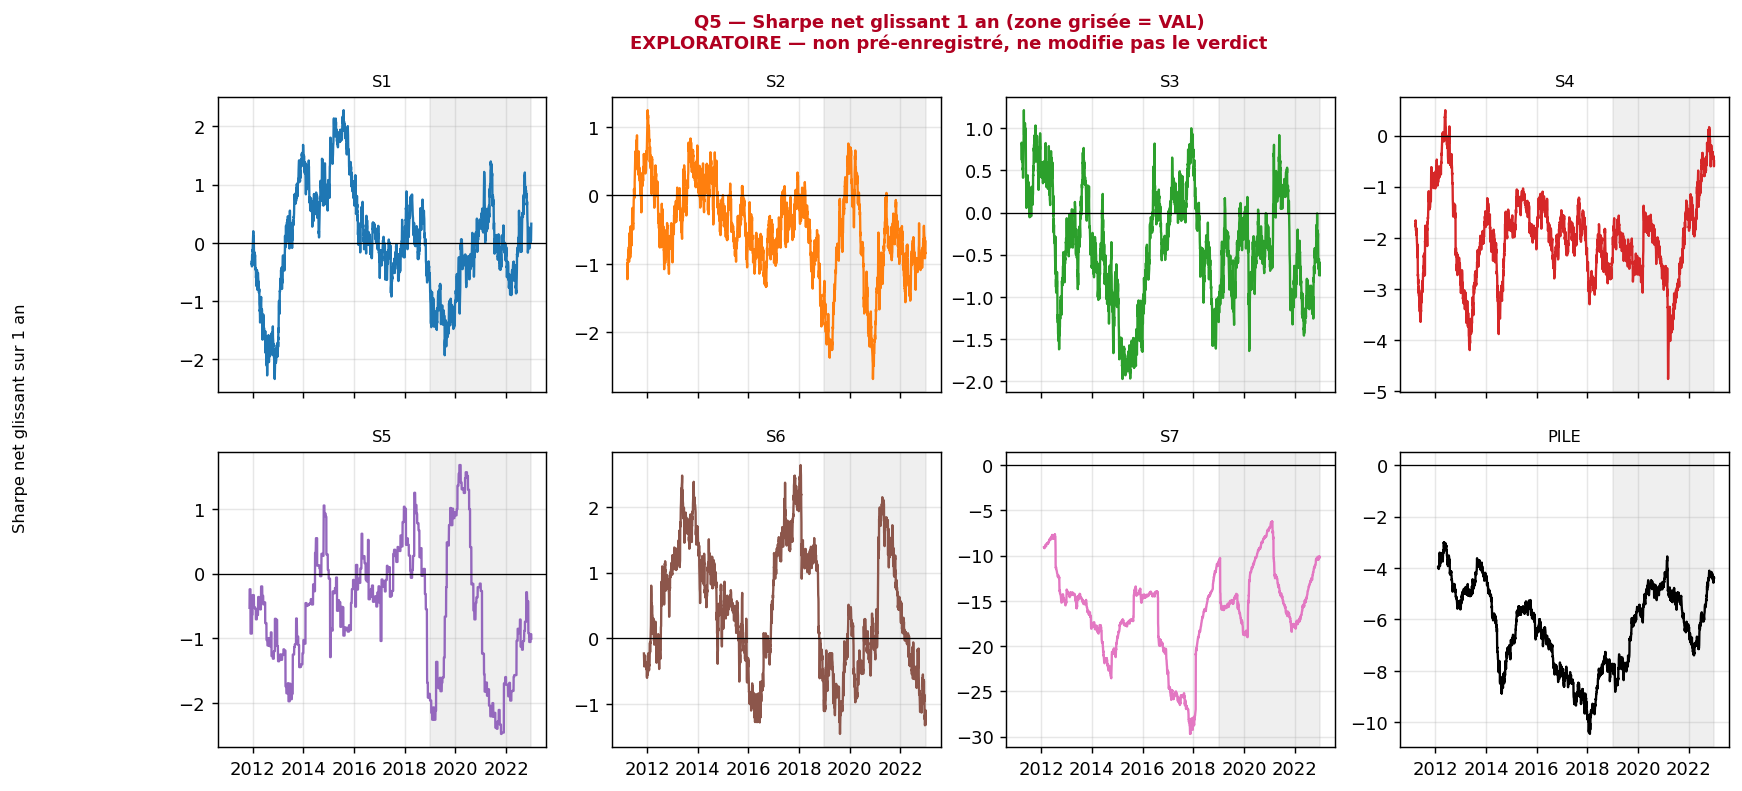

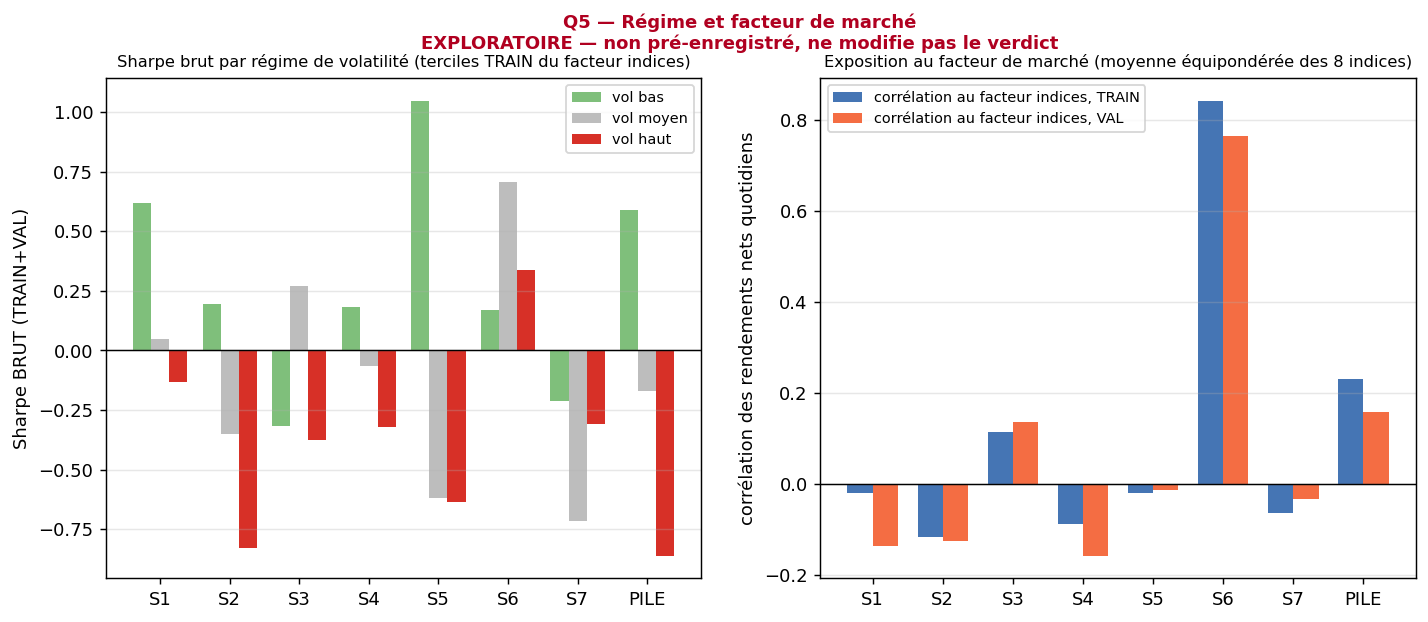

In [18]:
lignes = []
for nom, v in q5["sleeves"].items():
    lignes.append({"série": nom, "Sharpe annuel min": min(v["sharpe_annuel_calendaire_net"].values()), "max": max(v["sharpe_annuel_calendaire_net"].values()),
                   "part d'années > 0": v["part_annees_sharpe_net_positif"], "Q": v["constance"]["q"], "p (constance)": v["constance"]["p_constance"],
                   "glissant 1 an : écart-type": v["sharpe_glissant_1an_net"]["ecart_type"], "corr. indices TRAIN": v["facteur"]["TRAIN"]["indices"]["correlation"],
                   "corr. indices VAL": v["facteur"]["VAL"]["indices"]["correlation"], "bêta indices VAL": v["facteur"]["VAL"]["indices"]["beta"],
                   "corr. 58 actifs VAL": v["facteur"]["VAL"]["tous_actifs"]["correlation"]})
display(pd.DataFrame(lignes).set_index("série").round(3))
display(pd.DataFrame({nom: {g: v["regime"][g]["sharpe_brut"] for g in ("bas", "moyen", "haut")} for nom, v in q5["sleeves"].items()}).T.round(2))
print("bornes des terciles de vol (TRAIN) :", [round(x, 3) for x in q5["regime_vol"]["seuils_terciles_train"]])
tab = pd.DataFrame({nom: {"cause principale": v["cause"]["cause"], "précision": v["cause"]["precision"]} for nom, v in q5["sleeves"].items()}).T
display(tab)
display(Image(str(FIG / "appro_q5_sharpe_glissant.png")))
display(Image(str(FIG / "appro_q5_regimes_facteur.png")))

**Conclusion / limites.**

In [19]:
aff(R["conclusions"]["Q5"])

Aucune sleeve n'a un Sharpe brut >= 0,30 sur TRAIN et VAL à la fois (meilleur brut VAL : 0,14). Cause principale (règle explicite) : S1 = pas d'alpha brut ; S2 = pas d'alpha brut ; S3 = pas d'alpha brut ; S4 = pas d'alpha brut (+ coût amplificateur) ; S5 = pas d'alpha brut ; S6 = régime (bêta actions : alpha brut présent sur une seule des deux périodes) ; S7 = pas d'alpha brut (+ coût amplificateur). Les Sharpe annuels de S1, S2, S3, S5, S6 sont compatibles avec un Sharpe constant (p de constance >= 0,43) : ce n'est pas un effet de régime mais un edge nul ou négatif à toute époque. S6 est surtout du bêta actions (corrélation 0,76 au facteur indices en VAL).

*Limites.* Le seuil de 0,30 (≈ 0,6 erreur-type d'un Sharpe sur 4 ans) est un choix explicite : la règle classe, elle ne prouve pas. Les Sharpe par régime et par année reposent sur peu d'observations (S5 : 12 trades par an et par paire, kurtosis 68) : à lire comme des ordres de grandeur.
Le facteur « 58 actifs équipondérés » mélange des paires cotées dans les deux sens contre l'USD (un signe arbitraire) : c'est pourquoi le facteur « 8 indices » est montré à côté. Les coûts sont ceux du fichier, constants sur toute la période.

## Q6. La diversification peut-elle suffire ?

> **EXPLORATOIRE — ne modifie pas le verdict pré-enregistré.** Analyse a posteriori sur TRAIN (≤ 2018) et VAL (2019-2022). Le TEST (≥ 2023) reste scellé, aucun paramètre des sleeves n'est touché, `PREREGISTRATION.md` n'est pas modifié (pas de nouvel avenant).

**Question.** Combien de sleeves de Sharpe net $s$, de corrélation moyenne $\bar\rho$ (observée en VAL), faut-il empiler pour atteindre 2 ?

**Intuition.** Additionner des paris indépendants fait monter le Sharpe comme $\sqrt N$ ; mais la moindre corrélation le plafonne : au-delà d'un certain nombre de sleeves on ne diversifie plus rien. Et diversifier ne crée pas d'edge : cela multiplie un Sharpe individuel qui doit déjà exister.

**Théorème.** $N$ sleeves de Sharpe $s$, de volatilité égale et de corrélation moyenne $\bar\rho$, en risque égal :
$$SR_{\text{pile}}=s\sqrt{\frac{N}{1+(N-1)\bar\rho}}\;\xrightarrow[N\to\infty]{}\;\frac{s}{\sqrt{\bar\rho}},\qquad N_{\text{requis}}(SR^\star)=\frac{{SR^\star}^2(1-\bar\rho)}{s^2-{SR^\star}^2\bar\rho}\quad(\text{impossible si } s^2\le {SR^\star}^2\bar\rho).$$
Avec les vrais Sharpe $s_i$ et la vraie corrélation $\mathbf R$ (risque égal) : $SR=\dfrac{\sum_i s_i}{\sqrt{\mathbf 1^\top\mathbf R\,\mathbf 1}}$.

**Attente.** Sous indépendance il faut 16 sleeves à 0,5 ; avec $\bar\rho\approx0{,}026$, environ 27. Et la formule doit retrouver le Sharpe réalisé de la pile (−5,3) en y mettant les Sharpe réels.

**Expérience.**

In [20]:
q6 = R["Q6_diversification"]
rho = q6["rho_moyen_val"]
lignes = []
for s in (0.3, 0.5, 0.7, 1.0):
    for r_ in (0.0, rho, 0.05, 0.10):
        lignes.append({"s": s, "rho": round(r_, 3), "N requis": theorie.n_sleeves_requis(s, r_), "plafond s/racine(rho)": (s / np.sqrt(r_) if r_ > 0 else np.inf)})
display(pd.DataFrame(lignes).pivot(index="s", columns="rho", values="N requis").round(1))
noms = ["S1", "S2", "S3", "S4", "S5", "S6", "S7"]
corr = pd.DataFrame(TV["correlations"]["VAL"]).loc[noms, noms].to_numpy()
s_val = np.array([TV["series"][k]["VAL"]["sharpe_net"] for k in noms])
m = theorie.sharpe_pile_matrice(s_val, corr)
print(f"corrélation moyenne observée (VAL) : {theorie.correlation_moyenne(corr):.4f}")
print(f"pile à risque égal avec les Sharpe réels : formule {m['risque_egal']:.2f}  vs réalisée {TV['series']['PILE']['VAL']['sharpe_net']:.2f}")

rho,0.000,0.026,0.050,0.100
s,,,,
0.3,44.4,inf,inf,inf
0.5,16.0,26.6,76.0,inf
0.7,8.2,10.1,13.1,40.0
1.0,4.0,4.3,4.7,6.0


corrélation moyenne observée (VAL) : 0.0259
pile à risque égal avec les Sharpe réels : formule -5.66  vs réalisée -5.30


**Résultat.**

{'rho_moyen_val': 0.02591904761904761, 'n_sleeves_requis_sharpe_05_rho_observe': 26.628091642801344, 'n_sleeves_requis_sharpe_05_independantes': 16.0, 'sharpe_individuel_requis_avec_7_sleeves': 0.8125846894638247, 'sharpe_pile_si_7_sleeves_de_sharpe_05': 1.2306409571411434, 'plafond_sharpe_pile_sleeves_05_rho_observe': 3.1057070259137802, 'meilleur_sharpe_net_val': 0.06513029308141277, 'meilleure_sleeve': 'S6', 'pile_formule_risque_egal_avec_sharpe_reels': -5.659205441510952, 'pile_optimale_theorique_sharpe_reels': 12.609614311879424, 'pile_realisee_val': -5.302098799428685}


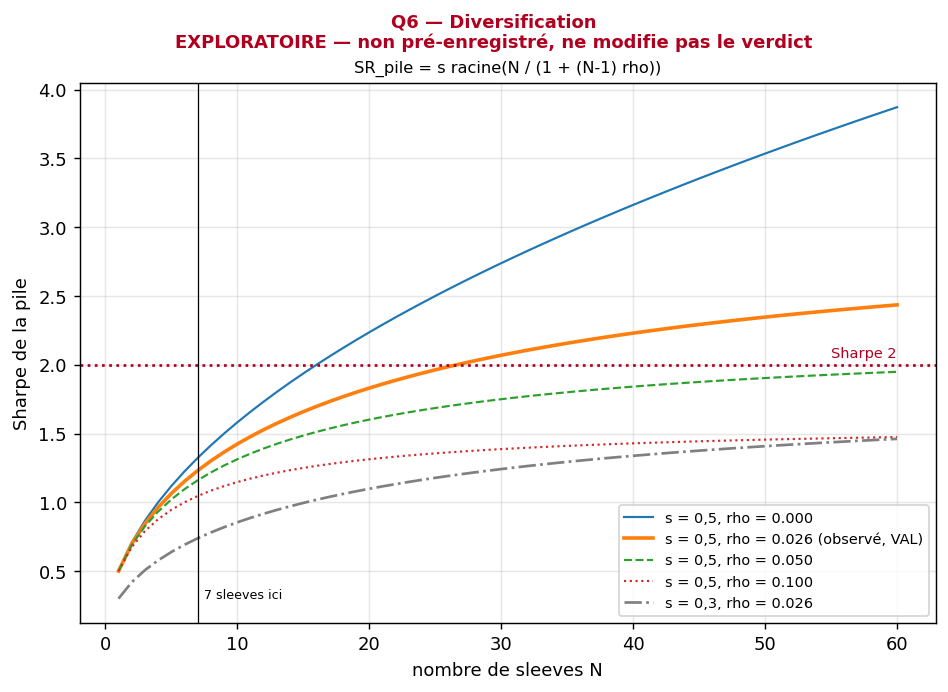

In [21]:
print({k: q6[k] for k in ("rho_moyen_val", "n_sleeves_requis_sharpe_05_rho_observe", "n_sleeves_requis_sharpe_05_independantes", "sharpe_individuel_requis_avec_7_sleeves",
                          "sharpe_pile_si_7_sleeves_de_sharpe_05", "plafond_sharpe_pile_sleeves_05_rho_observe", "meilleur_sharpe_net_val", "meilleure_sleeve",
                          "pile_formule_risque_egal_avec_sharpe_reels", "pile_optimale_theorique_sharpe_reels", "pile_realisee_val")})
display(Image(str(FIG / "appro_q6_diversification.png")))

**Conclusion / limites.**

In [22]:
aff(R["conclusions"]["Q6"])

Avec la corrélation moyenne observée en VAL (0,026), il faut 27 sleeves de Sharpe net 0,5 (16 si indépendantes) pour atteindre 2, ou 0,81 de Sharpe net par sleeve avec 7 sleeves. Le meilleur Sharpe net VAL ici est 0,07 (S6). La formule à risque égal retrouve le Sharpe de la pile (-5,66 prédit contre -5,30 réalisé) : la diversification multiplie un Sharpe moyen, elle n'en crée pas.

*Limites.* La corrélation moyenne est estimée sur 4 ans (comme les Sharpe) ; la formule suppose des Sharpe et des volatilités égaux. Chercher 27 sleeves « de Sharpe vrai 0,5 » est lui-même soumis à la Q4 : parmi des sleeves candidates, repérer celles qui ont vraiment 0,5 demande des
décennies d'historique (Q3). Le « Sharpe optimal théorique » avec les Sharpe réalisés est de l'in-sample : il n'est donné qu'à titre de borne.

## Q7 (bonus). Quelle capacité pour S1 et S6 ?

> **EXPLORATOIRE — ne modifie pas le verdict pré-enregistré.** Analyse a posteriori sur TRAIN (≤ 2018) et VAL (2019-2022). Le TEST (≥ 2023) reste scellé, aucun paramètre des sleeves n'est touché, `PREREGISTRATION.md` n'est pas modifié (pas de nouvel avenant).

**Question.** À partir de quel capital l'impact de marché mange-t-il le rendement net de S1 (trend following) et de S6 (actions gérées par la vol) ?

**Intuition.** Les coûts du fichier sont des coûts de petit porteur (spread fixe). Un gros capital déplace le prix : le coût par dollar traité croît avec la taille de l'ordre.

**Théorème (impact en racine carrée, Almgren ; Bouchaud).** Un ordre de taille $Q$ sur un actif d'écart-type journalier $\sigma$ et de volume journalier $V$ coûte en fraction du montant traité $Y\sigma\sqrt{Q/V}$. Pour un capital $A$ et des variations de position $|\Delta e_{t,i}|$ (fraction du capital) :
$$\text{impact annuel}(A)=\sqrt A\;K,\qquad K=\frac1{\text{années}}\sum_{t,i}\frac{Y\,\sigma_{t,i}\,|\Delta e_{t,i}|^{3/2}}{\sqrt{V_i}},\qquad A_{\max}=\Big(\frac{r_{\text{net avant impact}}}{K}\Big)^2 .$$

**Attente.** Avec des volumes de grandes liquidités, l'impact reste négligeable jusqu'à des milliards : la capacité ne sera pas le goulot.

**Expérience.** Hypothèses d'ordre de grandeur, **non sourcées** (le fichier de prix n'a pas de volume, le volume FX est nul) : ADV de 1e10 $/jour par paire FX, 5e10 par indice, 5e9 par matière première ; $Y=1$. À remplacer par les volumes réels du courtier.

In [23]:
q7 = R["Q7_capacite"]
print(q7["hypotheses"])

{'ADV_usd_par_jour': {'FX': 10000000000.0, 'Indice': 50000000000.0, 'Matière': 5000000000.0}, 'Y': 1.0, 'avertissement': "volumes et préfacteur d'ordre de grandeur, NON sourcés ; capacité ∝ ADV, ∝ (rendement net avant impact)^2"}


**Résultat.**

brut/an  coût réel/an  net avant impact  impact/an à 1e8 $  impact/an à 1e9 $  capacité (Md$)  $ où impact = coût réel (Md$)
sleeve période                                                                                                                              
S1     TRAIN     0.0246        0.0072            0.0174             0.0008             0.0026         43.6642                         7.5765
       VAL      -0.0127        0.0095           -0.0222             0.0010             0.0033          0.0000                         8.2186
S6     TRAIN     0.0564        0.0048            0.0516             0.0005             0.0015       1215.3933                        10.7270
       VAL       0.0125        0.0059            0.0066             0.0007             0.0022          8.9609                         7.3258

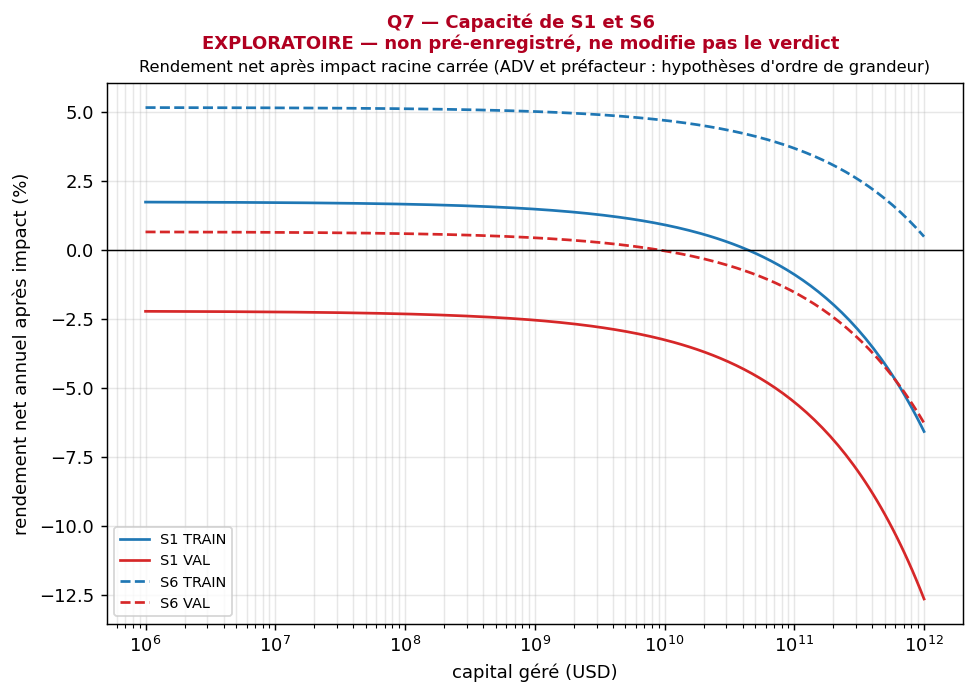

In [24]:
lignes = []
for nom, blocs in q7["sleeves"].items():
    for p, b in blocs.items():
        lignes.append({"sleeve": nom, "période": p, "brut/an": b["rendement_brut_annuel"], "coût réel/an": b["cout_reel_annuel"], "net avant impact": b["rendement_net_avant_impact"],
                       "impact/an à 1e8 $": b["impact_annuel_a_1e8_usd"], "impact/an à 1e9 $": b["impact_annuel_a_1e9_usd"],
                       "capacité (Md$)": b["capacite_usd"] / 1e9, "$ où impact = coût réel (Md$)": (b["usd_ou_impact_egale_cout_reel"] or 0) / 1e9})
display(pd.DataFrame(lignes).set_index(["sleeve", "période"]).round(4))
display(Image(str(FIG / "appro_q7_capacite.png")))

**Conclusion / limites.**

In [25]:
aff(R["conclusions"]["Q7"])

Sous l'hypothèse non sourcée d'ADV de 1e10 \$/jour en FX et 5e10 en indices, l'impact racine carrée à 1 Md\$ coûte 0,33 %/an pour S1 et 0,22 %/an pour S6 : la capacité n'est pas le goulot. Capacité (rendement net = 0) : S1 TRAIN 44 Md\$, S1 VAL 0 (brut négatif), S6 TRAIN 1215 Md\$, S6 VAL 9 Md\$ ; elle est proportionnelle à l'ADV supposé (ADV x 0,1 => capacité x 0,1) et au carré du rendement net avant impact. Le goulot reste l'edge brut.

*Limites.* Ordre de grandeur uniquement : volumes supposés, un seul préfacteur, loi en racine carrée supposée valable bien au-delà de son domaine calibré, pas d'impact croisé entre sleeves ni de décroissance de l'impact. Capacité ∝ ADV ; ×0,1 sur l'ADV donne ×0,1 sur la capacité.
Pour S1 en VAL (brut négatif) et toute sleeve à brut ≤ coût, la capacité est nulle quelle que soit l'ADV.

## Ce qu'il faudrait de vrai pour un Sharpe net > 2

> **EXPLORATOIRE — ne modifie pas le verdict pré-enregistré.** Analyse a posteriori sur TRAIN (≤ 2018) et VAL (2019-2022). Le TEST (≥ 2023) reste scellé, aucun paramètre des sleeves n'est touché, `PREREGISTRATION.md` n'est pas modifié (pas de nouvel avenant).

In [26]:
for i, ligne in enumerate(R["conclusions"]["synthese_pour_sharpe_2"], 1):
    aff(f"{i}. {ligne}")

1. Loi fondamentale : pour IR = 2 avec ~1792 paris/an, il faut un IC de 0,059 sur chaque sleeve ; observé -0,047.

2. Puissance : 4 ans de VAL ne détectent qu'un Sharpe >= 1,22 (1,62 avec 7 tests) ; confirmer un vrai Sharpe de 0,5 prend 25 ans.

3. Diversification : 27 sleeves de Sharpe net 0,5 à rho = 0,026 ; le meilleur Sharpe net VAL ici est 0,07.

4. Tests multiples : sur la durée de VAL (4,1 ans) le hasard fabrique un Sharpe de 2 après 24121 essais, de 1 après 28 : un vrai résultat doit survivre à la déflation par le N réel et à un TEST à lecture unique.

5. Ce qui est vrai ici : le goulot est l'edge brut (Sharpe brut VAL <= 0,14 pour toutes les sleeves, pile -0,70), ni les coûts, ni la capacité, ni le régime ; baisser les coûts ne crée pas d'edge.

En une phrase : **un Sharpe net de 2 demande soit un IC durable de l'ordre de 0,06 sur toutes les sleeves d'une pile de ~1 800 paris indépendants par an, soit ~27 sleeves de Sharpe net réel 0,5 peu corrélées, chacune confirmée par des
décennies de données, sous déflation par le N d'essais réel et lue une seule fois sur un TEST scellé.** Rien de tel n'existe dans les 7 sleeves de la littérature essayées ici.

Ce carnet est **exploratoire** : il ne change ni le verdict `ECHEC`, ni le pré-enregistrement, ni le statut du TEST (scellé).